In [1]:
import torch
import torchvision
from torchvision import transforms,models
from torch.utils.data import random_split,DataLoader
import numpy as np
import torchvision
import matplotlib.pyplot as plt
import torch.nn as nn


In [2]:
transform = transforms.Compose([
    transforms.Lambda(lambda img: img.convert("RGB")),  # force RGB
    transforms.Resize((128,128)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5,0.5,0.5],
        std=[0.5,0.5,0.5]
    )
])

dataset = torchvision.datasets.Caltech101(
    root='./data',      # download location
    download=True,      # auto download dataset
    transform=transform
)


In [3]:
dataset.categories


['Faces',
 'Faces_easy',
 'Leopards',
 'Motorbikes',
 'accordion',
 'airplanes',
 'anchor',
 'ant',
 'barrel',
 'bass',
 'beaver',
 'binocular',
 'bonsai',
 'brain',
 'brontosaurus',
 'buddha',
 'butterfly',
 'camera',
 'cannon',
 'car_side',
 'ceiling_fan',
 'cellphone',
 'chair',
 'chandelier',
 'cougar_body',
 'cougar_face',
 'crab',
 'crayfish',
 'crocodile',
 'crocodile_head',
 'cup',
 'dalmatian',
 'dollar_bill',
 'dolphin',
 'dragonfly',
 'electric_guitar',
 'elephant',
 'emu',
 'euphonium',
 'ewer',
 'ferry',
 'flamingo',
 'flamingo_head',
 'garfield',
 'gerenuk',
 'gramophone',
 'grand_piano',
 'hawksbill',
 'headphone',
 'hedgehog',
 'helicopter',
 'ibis',
 'inline_skate',
 'joshua_tree',
 'kangaroo',
 'ketch',
 'lamp',
 'laptop',
 'llama',
 'lobster',
 'lotus',
 'mandolin',
 'mayfly',
 'menorah',
 'metronome',
 'minaret',
 'nautilus',
 'octopus',
 'okapi',
 'pagoda',
 'panda',
 'pigeon',
 'pizza',
 'platypus',
 'pyramid',
 'revolver',
 'rhino',
 'rooster',
 'saxophone',
 'sc

In [4]:
train_size=int(len(dataset)*0.8)
test_size = len(dataset)-train_size

In [5]:
train_dataset,test_dataset=random_split(dataset,[train_size,test_size])

In [6]:
train_loader=DataLoader(train_dataset,batch_size=12,shuffle=True)
test_loader=DataLoader(test_dataset,batch_size=12,shuffle=False)

In [7]:
for i,(images,labels) in enumerate(train_loader):
    print(images.shape)
    print(labels.shape)
    break

torch.Size([12, 3, 128, 128])
torch.Size([12])


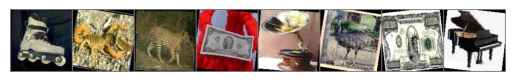

In [8]:
def imshow(img):
    img = img / 2 + 0.5   # unnormalize
    npimg = img.numpy()

    # Correct transpose: (C,H,W) → (H,W,C)
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.axis("off")
    plt.show()

# Show images
imshow(torchvision.utils.make_grid(images[:8]))


In [9]:
labels[:8]

tensor([52, 81,  2, 32, 45, 37, 32, 46])

In [10]:
len(dataset.categories)

101

In [11]:
[dataset.categories[i] for i in labels[:8] ] 

['inline_skate',
 'scorpion',
 'Leopards',
 'dollar_bill',
 'gramophone',
 'emu',
 'dollar_bill',
 'grand_piano']

In [12]:
class CNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.network=nn.Sequential(
            nn.Conv2d(3,32,kernel_size=(3,3),padding="same"), # output (32,128,128)
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2,2),stride=(2,2)),# output(32,64,64)
            nn.Conv2d(32,64,kernel_size=(3,3),padding="same"), #(64,64,64)
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2,2),stride=(2,2)), #(64,32,32)

            nn.Flatten(),
            nn.Linear(64*32*32, 256),
            nn.ReLU(),
            nn.Linear(256,num_classes)

        )
    def forward(self,x):
        return self.network(x)

In [13]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device) 

cpu


In [14]:
CNN(len(dataset.categories))

CNN(
  (network): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (1): ReLU()
    (2): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=same)
    (4): ReLU()
    (5): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
    (6): Flatten(start_dim=1, end_dim=-1)
    (7): Linear(in_features=65536, out_features=256, bias=True)
    (8): ReLU()
    (9): Linear(in_features=256, out_features=101, bias=True)
  )
)

In [15]:
def train_model(model, optimizer, criterion, train_loader, test_loader, num_epochs=5):

    for epoch in range(num_epochs):

        # Set model to training mode
        model.train()

        running_loss = 0.0

        for images, labels in train_loader:

            # Move data to device (GPU/CPU)
            images = images.to(device)
            labels = labels.to(device)

            # Clear previous gradients
            optimizer.zero_grad()

            # Forward pass
            outputs = model(images)

            # Calculate loss
            loss = criterion(outputs, labels)

            # Backpropagation
            loss.backward()

            # Update weights
            optimizer.step()

            # Accumulate loss
            running_loss += loss.item()

        print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {running_loss/len(train_loader):.4f}")


In [16]:
no_of_classes=len(dataset.categories)
# Create model
model = CNN(no_of_classes).to(device)

# Loss function
criterion = nn.CrossEntropyLoss()
import torch.optim as optim

# Optimizer
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Train model
train_model(model, optimizer, criterion, train_loader, test_loader, num_epochs=5)



Epoch [1/5], Loss: 3.3409
Epoch [2/5], Loss: 2.4612
Epoch [3/5], Loss: 2.0003
Epoch [4/5], Loss: 1.6926
Epoch [5/5], Loss: 1.4442


In [17]:
def test_model(model, test_loader):

    # Set model to evaluation mode
    model.eval()

    correct = 0
    total = 0

    # Disable gradient calculation
    with torch.no_grad():

        for images, labels in test_loader:

            # Move data to device
            images = images.to(device)
            labels = labels.to(device)

            # Forward pass
            outputs = model(images)

            # Get predicted class
            _, predicted = torch.max(outputs, 1)

            # Count total samples
            total += labels.size(0)

            # Count correct predictions
            correct += (predicted == labels).sum().item()

    print(f"Test Accuracy: {(100 * correct / total):.2f}%")


In [18]:
test_model(model,test_loader)

Test Accuracy: 55.18%


# Transfer Learning

In [19]:
from torchvision import models

model=models.resnet18(weights="DEFAULT")
model.fc=nn.Linear(model.fc.in_features,no_of_classes)

In [20]:
model=model.to(device)
criterion = nn.CrossEntropyLoss()
import torch.optim as optim

# Optimizer
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Train model
train_model(model, optimizer, criterion, train_loader, test_loader, num_epochs=5)


Epoch [1/5], Loss: 2.6512
Epoch [2/5], Loss: 1.6467
Epoch [3/5], Loss: 1.1973
Epoch [4/5], Loss: 0.9784
Epoch [5/5], Loss: 0.7944


In [21]:
test_model(model,test_loader)

Test Accuracy: 71.26%


In [22]:
# Load EfficientNet-B0 model with pretrained weights
model = models.efficientnet_b0(weights='DEFAULT')

# Modify classifier for your number of classes
model.classifier[1] = nn.Linear(
    model.classifier[1].in_features,
    no_of_classes
)

# Move model to device (CPU/GPU)
model = model.to(device)

# Define loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Train and evaluate
train_model(model, optimizer, criterion, train_loader, test_loader, num_epochs=5)
test_model(model, test_loader)



Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to C:\Users\Trijesh Kondapuram/.cache\torch\hub\checkpoints\efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:33<00:00, 640kB/s] 


Epoch [1/5], Loss: 1.6909
Epoch [2/5], Loss: 0.7996
Epoch [3/5], Loss: 0.5693
Epoch [4/5], Loss: 0.4467
Epoch [5/5], Loss: 0.3946
Test Accuracy: 86.46%
